# Ocean.stats diagnostics (`ocean.stats.nc`)

MOM6 writes a per-timestep integration-diagnostics file, `ocean.stats` (plain text)
and `ocean.stats.nc` (its netCDF equivalent) -- energy, max CFL, mean sea level,
total mass, mean salinity/temperature, and their conservation errors over the
course of the run. This notebook finds `ocean.stats.nc` via the intake-esm
datastore and plots each diagnostic.

See discussion in [access-om3-paper-1#23](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/23)
and [access-nri-intake-catalog#682](https://github.com/ACCESS-NRI/access-nri-intake-catalog/issues/682).

The first draft of thie notebook was written with Claude (prompted by @chrisb13)

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.*
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory
nbname = None                          # notebook name


In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/"
nbname = "ocean_stats.ipynb"


In [3]:
if not papermill:
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)


In [4]:
import intake
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np


### Open the intake-esm datastore and find `ocean.stats.nc`

In [5]:
COLUMNS_WITH_ITERABLES = [
    "variable",
    "variable_long_name",
    "variable_standard_name",
    "variable_cell_methods",
    "variable_units",
]

datastore = intake.open_esm_datastore(esm_file, columns_with_iterables=COLUMNS_WITH_ITERABLES)
datastore.search(filename="ocean.stats.nc").df


,filename,path,file_id,frequency,start_date,end_date,variable,variable_long_name,variable_standard_name,variable_cell_methods,variable_units,realm,temporal_label
0,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:60,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
1,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:62,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
2,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:62,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
3,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:93,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
4,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:93,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
5,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:91,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
6,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:92,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
7,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:93,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
8,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:93,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown
9,ocean.stats.nc,/g/data/ol01/outputs/access-om3-8km/MC_8km_jra...,ocean.fx.Interface:76.Layer:75.Time:91,fx,none,none,"(APE, En, H0, Heat, Heat_anom, Heat_chg, Inter...","(Total Interface APE, Total Energy, Zero APE D...","(, , , , , , , , , , , , , , , , , , , , )","(, , , , , , , , , , , , , , , , , , , , )","(Joules, Joules, meter, Joules, Joules, Joules...",ocean,unknown


### Load `ocean.stats.nc`

Loading `ocean.stats.nc` currently needs two workarounds:

1. The datastore's aggregation only recognises a lowercase `time` dimension when deciding how to join assets, but `ocean.stats.nc` uses `Time`. This means the 66 per-restart `ocean.stats.nc` files aren't concatenated -- they get grouped by `file_id` instead, based on each file's number of timesteps, collapsing everything into just two datasets. `aggregate_on_keys` below removes `file_id` from the aggregation so all matching files are joined into one dataset (see [access-nri-intake-catalog#682](https://github.com/ACCESS-NRI/access-nri-intake-catalog/issues/682) and [this PR discussion](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/pull/137#issuecomment-5673222494) for the full investigation).
2. `Time`'s `units` attribute looks timedelta-like to CF conventions, so xarray tries to decode it as `timedelta64[ns]` -- which overflows for a multi-century run. `decode_times=False` avoids that.

In [6]:
def aggregate_on_keys(ds, keys):
    """Drop `keys` from the datastore's aggregation groupby_attrs so matching
    assets are joined into one dataset instead of being split by those keys
    (workaround for the ocean.stats.nc `Time` vs `time` capitalisation bug --
    see access-nri-intake-catalog#682)."""
    parent_keys = ds.esmcat.aggregation_control.groupby_attrs
    missing_keys = set(keys) - set(parent_keys)
    if missing_keys:
        raise ValueError(f"Cannot remove non-existent aggregation keys: {missing_keys}")
    ds.esmcat.aggregation_control.groupby_attrs = [
        key for key in parent_keys if key not in keys
    ]
    return ds


ds_filtered = datastore.search(filename="ocean.stats.nc")
if ds_filtered.df.empty:
    raise FileNotFoundError(
        f"No ocean.stats.nc in the datastore {esm_file}. Either this run doesn't keep it "
        "or the datastore was built with analysis3-25.05 or "
        "earlier, whose AccessOm3Builder skips ocean.stats.nc: rebuild it with analysis3-26.08 or later."
    )
ds_filtered = aggregate_on_keys(ds_filtered, ["file_id"])

ocean_stats = ds_filtered.to_dask(xarray_open_kwargs=dict(decode_times=False))
ocean_stats

<xarray.Dataset> Size: 9MB
Dimensions:        (Time: 3682, Interface: 76, Layer: 75)
Coordinates:
  * Time           (Time) float64 29kB 6.931e+05 6.931e+05 ... 6.968e+05
  * Interface      (Interface) float64 608B 0.0 1.083 2.279 ... 5.61e+03 6e+03
  * Layer          (Layer) float64 600B 0.5413 1.681 ... 5.511e+03 5.805e+03
Data variables: (12/18)
    Ntrunc         (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    En             (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    APE            (Time, Interface) float64 2MB dask.array<chunksize=(60, 76), meta=np.ndarray>
    KE             (Time, Layer) float64 2MB dask.array<chunksize=(60, 75), meta=np.ndarray>
    H0             (Time, Interface) float64 2MB dask.array<chunksize=(60, 76), meta=np.ndarray>
    Mass_lay       (Time, Layer) float64 2MB dask.array<chunksize=(60, 75), meta=np.ndarray>
    ...             ...
    Salt_chg       (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    Salt_anom      (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    Heat           (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    Heat_chg       (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    Heat_anom      (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
    age            (Time) float64 29kB dask.array<chunksize=(60,), meta=np.ndarray>
Attributes: (12/15)
    filename:                                 ./ocean.stats.nc
    intake_esm_vars:                          ('APE', 'En', 'H0', 'Heat', 'He...
    intake_esm_attrs:filename:                ocean.stats.nc
    intake_esm_attrs:frequency:               fx
    intake_esm_attrs:start_date:              none
    intake_esm_attrs:end_date:                none
    ...                                       ...
    intake_esm_attrs:variable_cell_methods:   ,,,,,,,,,,,,,,,,,,,,
    intake_esm_attrs:variable_units:          Joules,Joules,meter,Joules,Joul...
    intake_esm_attrs:realm:                   ocean
    intake_esm_attrs:temporal_label:          unknown
    intake_esm_attrs:_data_format_:           netcdf
    intake_esm_dataset_key:                   unknown

### Plot each diagnostic over the run

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccfbdf9700>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccfb7f78c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccfb7f41d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccfbef3020>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccfbef2a20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccfbac5340>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccf9e07e30>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Calendar: 'noleap', 365.0 days per year


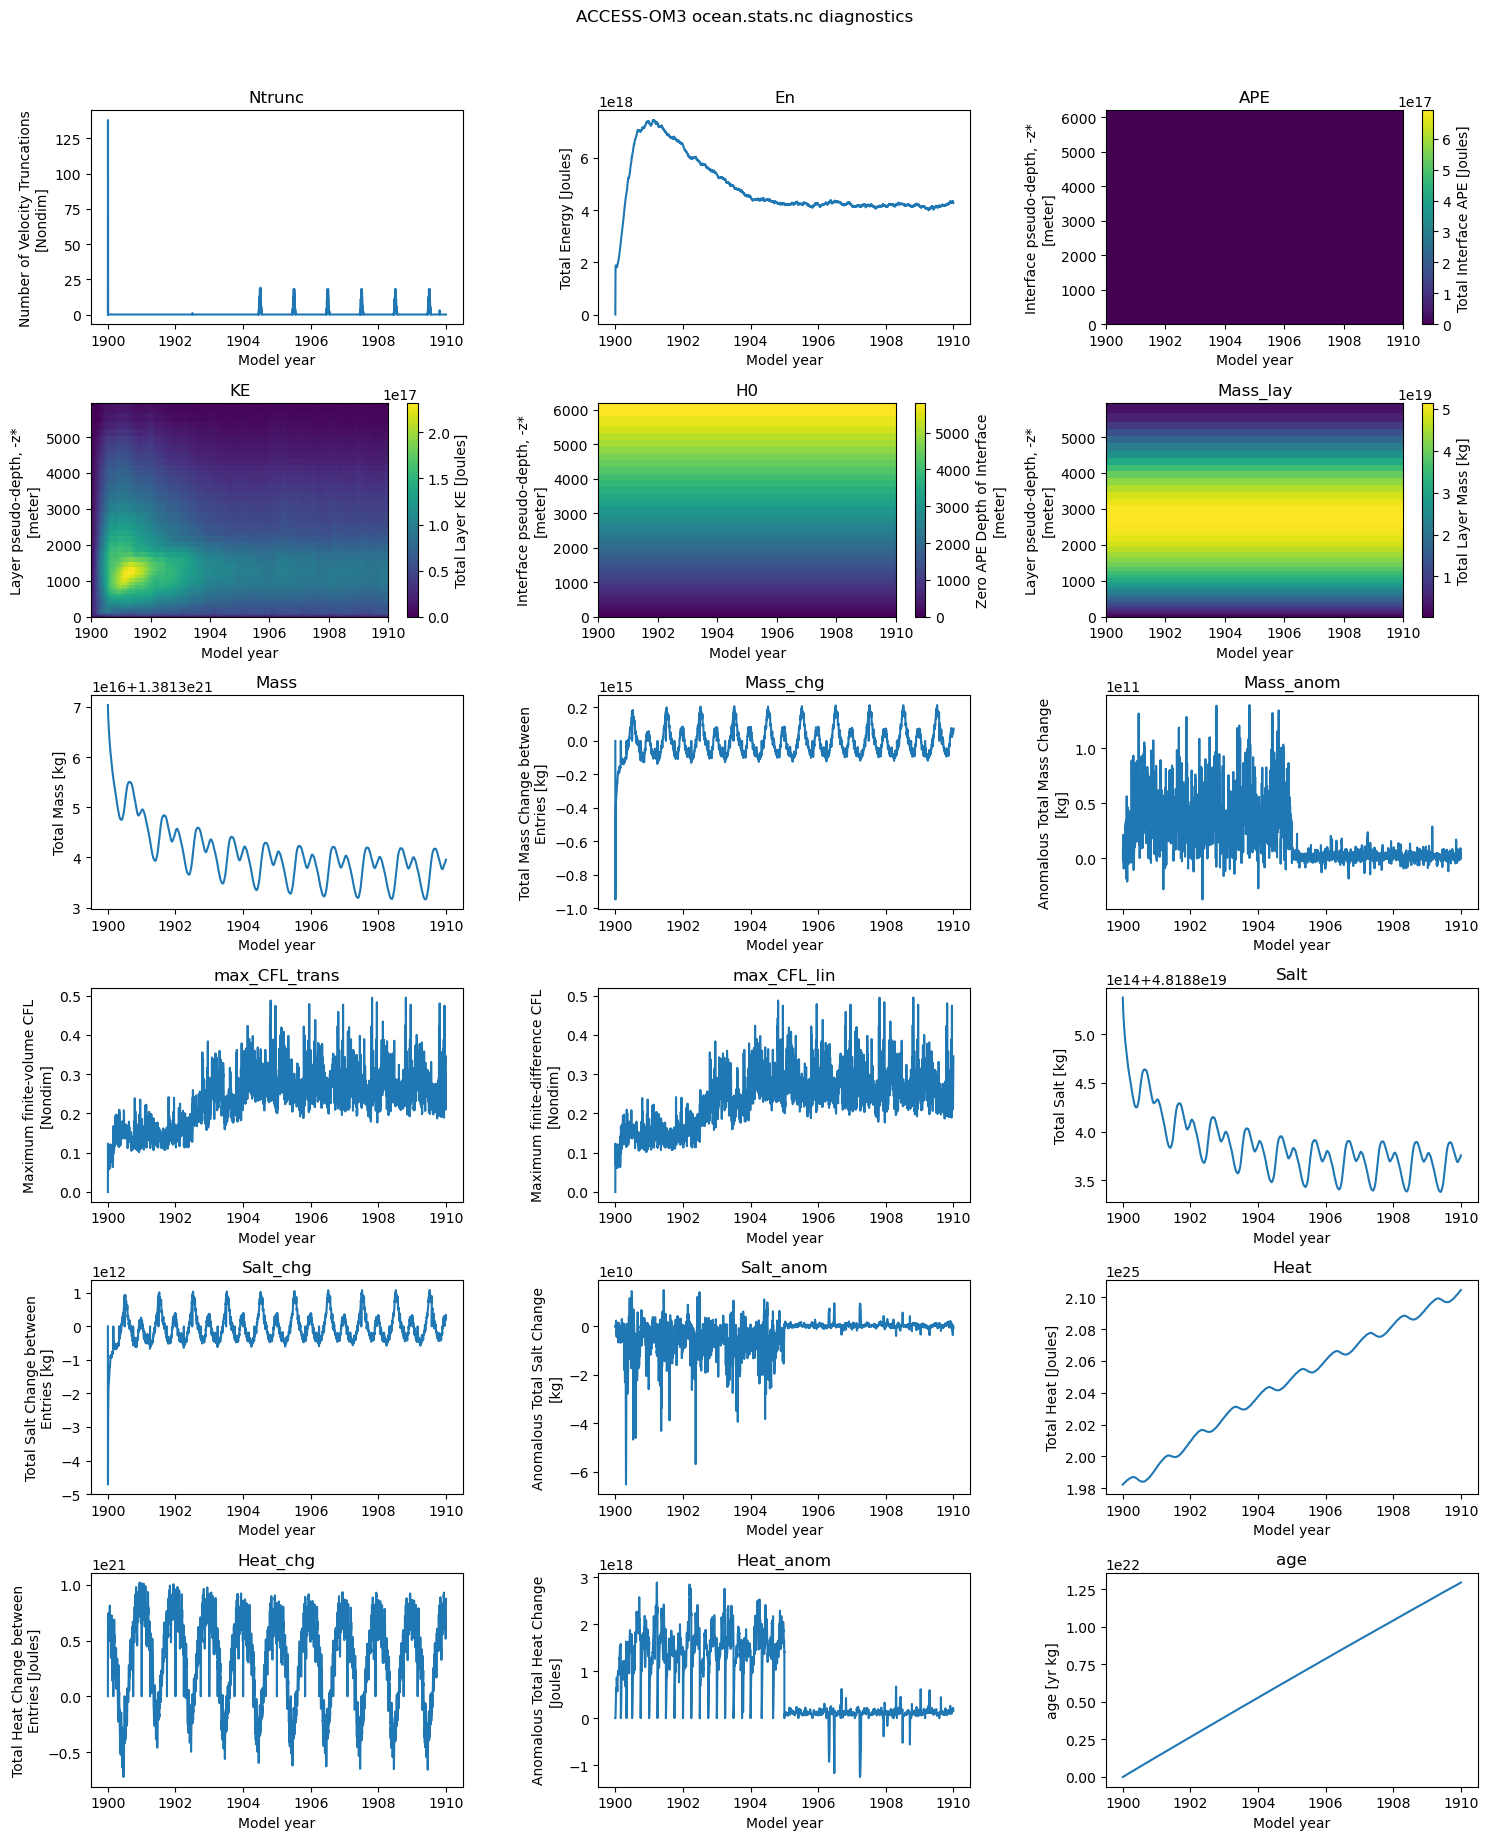

In [7]:
def get_calendar(ocean_stats, datastore):
    """The run's calendar, lowercased ('' if it can't be found). MOM6 doesn't write a
    `calendar` attribute to ocean.stats.nc, so take it from the time axis of the run's
    other ocean output (e.g. the MOM6 history files), which does have one."""
    calendar = ocean_stats["Time"].attrs.get("calendar", "")
    if calendar:
        return calendar.lower()
    others = datastore.search(realm="ocean").df
    others = others[others["frequency"] != "fx"]
    if others.empty:
        return ""
    with xr.open_dataset(others["path"].iloc[0], decode_times=False) as ds:
        return next((v.attrs["calendar"] for v in ds.variables.values() if "calendar" in v.attrs), "").lower()

# Time is raw days since 0001-01-01 in the run's calendar (decode_times=False avoids
# the calendar overflow). Convert to model years for a more readable axis: +1 because
# day 0 is the start of year 1.
DAYS_PER_YEAR = {
    "noleap": 365.0, "365_day": 365.0,
    "all_leap": 366.0, "366_day": 366.0,
    "360_day": 360.0,
    "julian": 365.25,
    "gregorian": 365.2425, "standard": 365.2425, "proleptic_gregorian": 365.2425,
}
calendar = get_calendar(ocean_stats, datastore)
if not calendar:
    print("No calendar found for this run: assuming 365.25 days per year.")
elif calendar not in DAYS_PER_YEAR:
    print(f"Calendar {calendar!r} not recognised: assuming 365.25 days per year.")
days_per_year = DAYS_PER_YEAR.get(calendar, 365.25)

print(f"Calendar: {calendar!r}, {days_per_year} days per year")
ocean_stats = ocean_stats.assign_coords(Time_years=1 + ocean_stats["Time"] / days_per_year)

data_vars = [v for v in ocean_stats.data_vars if "Time" in ocean_stats[v].dims]

ncols = 3
nrows = -(-len(data_vars) // ncols)  # ceil division
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows), squeeze=False)

for ax, var in zip(axes.flat, data_vars):
    ocean_stats[var].plot(ax=ax, x="Time_years")
    ax.set_title(var)
    ax.set_xlabel("Model year")

for ax in axes.flat[len(data_vars):]:
    ax.axis("off")

fig.suptitle("ACCESS-OM3 ocean.stats.nc diagnostics", y=1.02)
fig.tight_layout()

In [8]:
# mkmd.savefig(fig, title, caption, dpi=100)
# Save figure and append to markdown summary.
mkmd.savefig(
    fig,
    "Ocean.stats diagnostics",
    "MOM6 integration diagnostics from ocean.stats.nc (energy, max CFL, mean sea "
    "level, total mass, mean salinity/temperature, and their conservation errors) "
    "over the course of the run.",
    dpi=150,
)


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/ocean_stats_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/ocean_stats.md


Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/ocean_stats.md successfully.
